## Black-Scholes Formula

In [8]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

def black_scholes(S, K, T, r, sigma, option_type):
    d1 = (np.log(S / K) + ((r + (sigma ** 2 / 2)) * T)) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option_type == "call":
        call = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
        return call
    elif option_type == "put":
        put = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)
        return put
    else:
        raise ValueError("Option type must be 'call' or 'put'")

In [9]:
call_price = (black_scholes(100, 100, 1, 0.05, 0.2, "call"))
print(call_price)
put_price = (black_scholes(100, 100, 1, 0.05, 0.2, "put"))
print(put_price)
print(call_price - put_price)
S = 100
K = 100
T = 1
r = 0.05
print(S - K * np.exp(-r * T))

10.450583572185565
5.573526022256971
4.877057549928594
4.877057549928594


## Binomial Convergence Chart

In [10]:
import numpy as np
def call_payoff(S, K):
    return np.maximum(S - K, 0)

def binomial_call(S0, K, r, sigma, T, n):
    dt = T / n
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    j = np.arange(n + 1)
    S_t = S0 * (u ** j) * (d ** (n - j))
    f = call_payoff(S_t, K)
    p = ((np.exp(r * dt)) - d) / (u - d)
    disc = np.exp(-r * dt)
    for _ in range(n):
        f = disc * (p * f[1:] + (1 - p) * f[:-1])
    return f[0]

binomial_call(S0=100, K=100, r=0.05, sigma=0.2, T=1, n=1000)

step_count = range(1, 201)
tree_prices = []
for n in step_count:
    tree_prices.append(binomial_call(S0=100, K=100, r=0.05, sigma=0.2, T=1, n=n))
print(tree_prices[:5])
print(tree_prices[-1])

[np.float64(12.162284964623943), np.float64(9.540501338582947), np.float64(11.043871091951113), np.float64(9.970522921901265), np.float64(10.805933920410084)]
10.44059125985994


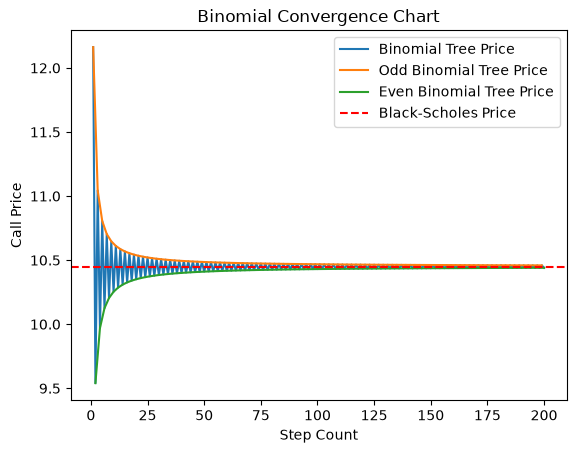

In [11]:
plt.plot(step_count, tree_prices, label = "Binomial Tree Price")
plt.plot(step_count[::2], tree_prices[::2], label = "Odd Binomial Tree Price")
plt.plot(step_count[1::2], tree_prices[1::2], label = "Even Binomial Tree Price")
plt.axhline(y = black_scholes(S=100, K=100, T=1, r=0.05, sigma=0.2, option_type="call"), linestyle="--", color="red", label="Black-Scholes Price")
plt.title("Binomial Convergence Chart")
plt.legend()
plt.ylabel("Call Price")
plt.xlabel("Step Count")
plt.show()

## Monte Carlo Chart
